# Model 1: Custom CNN Model

In [29]:
# Core
import numpy as np
import os
import pathlib

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom

# Pretrained models
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.callbacks import EarlyStopping

# Image loading and preprocessing
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluation
from sklearn.metrics import confusion_matrix, classification_report

# Utilities
import pandas as pd
from collections import Counter

### Load preprocessed data

In [4]:
import import_ipynb
from preprocessing import train_ds, val_ds, test_ds, class_names, data_augmentation, normalization_layer

# run this cell again to delete output from preprocessing 

### Architecture

We build a simple but effective convolutional network:

- 3 convolutional blocks  
- each block: Conv2D -> MaxPooling  
- Dropout for regularization  
- Flatten + Dense layers  
- Output: softmax with 5 classes  


In [20]:
num_classes = len(class_names)

model = Sequential([
    
    # Augmentation
    data_augmentation,
    
    # Normalization
    normalization_layer,
    
    # Convolutional Block 1
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),
    
    # Convolutional Block 2
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),
    
    # Convolutional Block 3
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D(),
    
    # Flatten and Dense layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    
    # Output layer
    layers.Dense(num_classes, activation='softmax')
])

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 224, 224, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (32, 224, 224, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (32, 224, 224, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (32, 112, 112, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (32, 112, 112, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (32, 56, 56, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (32, 56, 56, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (32, 28, 28, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (32, 100352)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (32, 128)              │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (32, 128)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (32, 5)                │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,077 (49.36 MB)

 Trainable params: 12,939,077 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

We use:

- Adam optimizer  
- Sparse categorical crossentropy  
- Accuracy as the main metric  


In [21]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Train the model

We use EarlyStopping during training. This automatically stops training when the validation loss stops improving, and restores the best-performing weights. Although configured for 200 epochs, the model completes training much earlier thanks to this.

In [30]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    callbacks=callbacks,
    epochs=200,
    verbose=0
)


### Training and Validation Curves

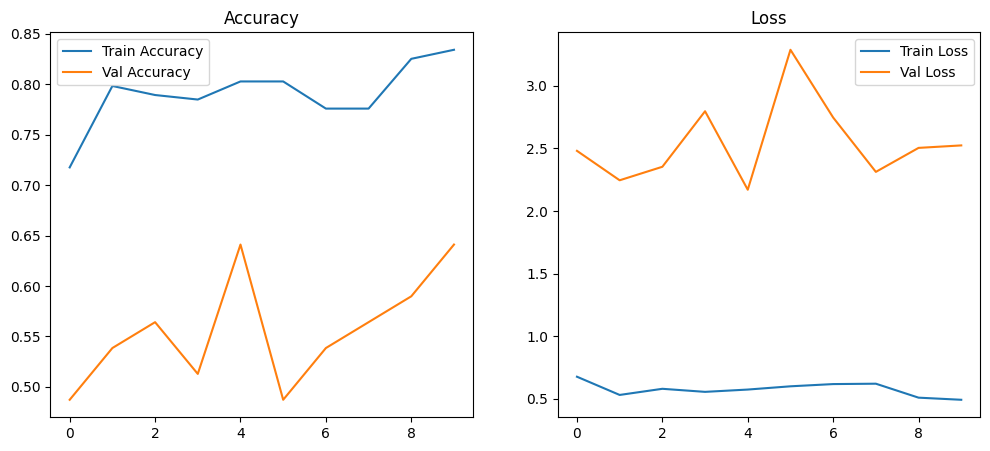

In [31]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, acc, label='Train Accuracy')
plt.plot(epochs, val_acc, label='Val Accuracy')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, loss, label='Train Loss')
plt.plot(epochs, val_loss, label='Val Loss')
plt.title("Loss")
plt.legend()

plt.show()


The curves show typical behavior for a small and complex dataset: the model learns the training data well, but validation accuracy fluctuates due to limited data and high variability.

### Test Set Evaluation

In [38]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.5490 - loss: 1.6565
Test accuracy: 0.5490


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


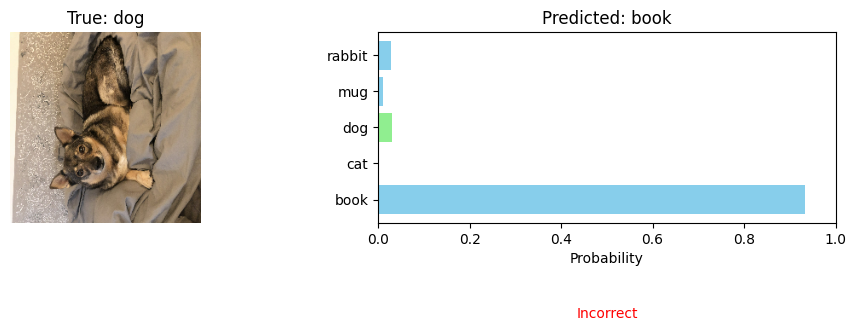

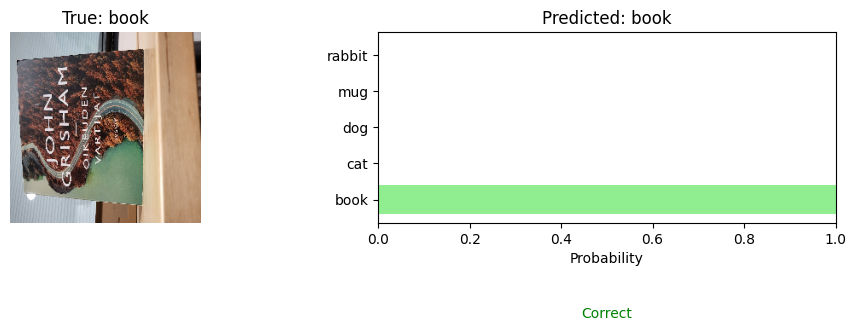

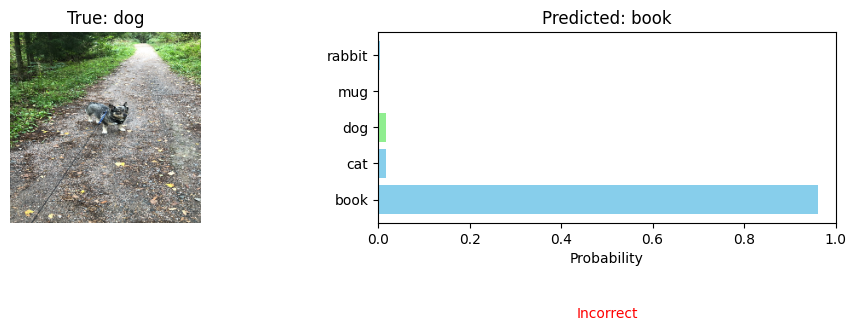

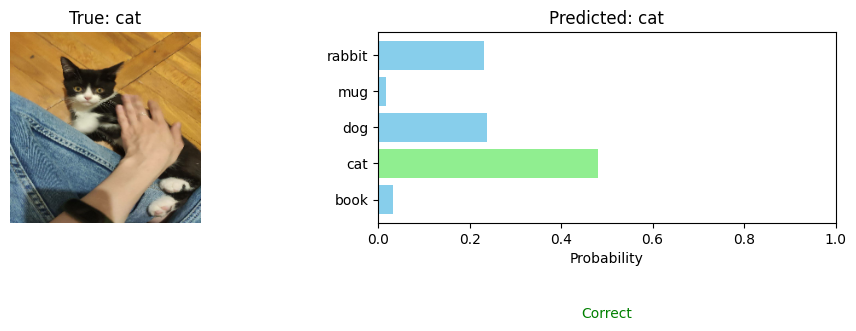

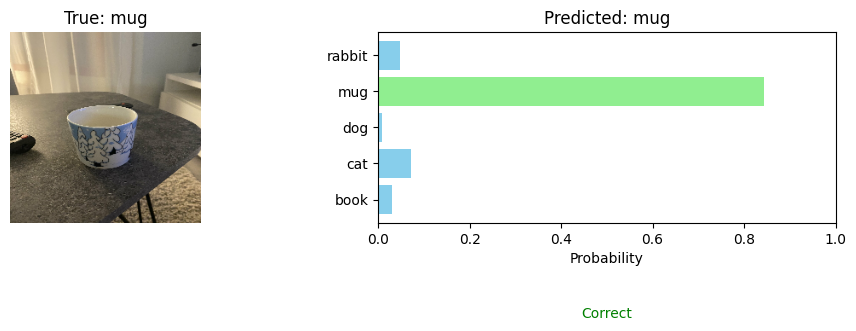

In [37]:
import random
import numpy as np
import matplotlib.pyplot as plt

# Pick one batch from test dataset
test_images, test_labels = next(iter(test_ds.take(1)))

# Predictions for the batch
predictions = model.predict(test_images)

# Convert to ints (sparse → already integers)
true_labels = test_labels.numpy()
predicted_labels = np.argmax(predictions, axis=1)


def plot_images(model):
    y_pred = []
    x_images = []
    y_true = []

    # Go through test_ds and collect everything
    for images, labels in test_ds:
        preds = model.predict(images, batch_size=32)
        y_pred.extend(preds)
        x_images.extend(images.numpy())
        y_true.extend(labels.numpy())   # sparse labels = integers

    y_pred = np.array(y_pred)
    x_images = np.array(x_images)
    y_true = np.array(y_true)

    # Random 5 samples
    num_samples = 5
    random_indices = random.sample(range(len(x_images)), num_samples)

    for i in random_indices:
        plt.figure(figsize=(10, 4))

        # LEFT: image
        plt.subplot(1, 2, 1)
        plt.imshow(x_images[i].astype("uint8"))
        true_class = class_names[int(y_true[i])]
        plt.title(f"True: {true_class}")
        plt.axis("off")

        # RIGHT: bar chart of predicted probabilities
        plt.subplot(1, 2, 2)
        pred_prob = y_pred[i]
        predicted_class = class_names[np.argmax(pred_prob)]

        # color bars: mark correct class green
        colors = [
            "lightgreen" if class_names[j] == true_class else "skyblue"
            for j in range(len(class_names))
        ]

        plt.barh(class_names, pred_prob, color=colors)
        plt.xlabel("Probability")
        plt.title(f"Predicted: {predicted_class}")
        plt.xlim([0, 1])

        # Add Correct/Incorrect label
        if predicted_class != true_class:
            plt.text(0.5, -0.5, "Incorrect", color="red",
                     ha="center", transform=plt.gca().transAxes)
        else:
            plt.text(0.5, -0.5, "Correct", color="green",
                     ha="center", transform=plt.gca().transAxes)

        plt.tight_layout()
        plt.show()


plot_images(model)


### Conclusion

The custom CNN model trained from scratch achieved an accuracy of approximately 50% on the test set.

This result is reasonable and expected, considering:

- the small size of the dataset
- the simple architecture of the model
- the high visual variability within the classes (animals, objects, different backgrounds, lighting conditions)

Therefore, in the next steps, the pretrained models (feature extraction and fine-tuning) are likely to achieve significantly higher accuracy, as they start from rich, general-purpose features learned from millions of images.


#### Use of AI

AI was primarily used to verify the code and the solution logic, as well as to generate plots.